# Notebook 4: Model Evaluation and Comparison

This notebook focuses on evaluating and comparing the performance of all trained machine learning models. We will use multiple evaluation metrics to get a comprehensive understanding of how well each model predicts Alzheimer's disease.

Proper evaluation is crucial for selecting the best model and understanding its strengths and weaknesses. We will examine accuracy, precision, recall, F1-score, and confusion matrices for each model.

## Loading Required Libraries

We import libraries for loading models, computing evaluation metrics, and creating visualizations. The scikit-learn metrics module provides all the evaluation tools we need.

In [1]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import cross_val_score

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')

## Loading Models and Data

We load the trained models and the test data that were saved in previous notebooks. This ensures we are evaluating the same models on the same unseen data.

In [2]:
with open('trained_models.pkl', 'rb') as f:
    models = pickle.load(f)

X_train = np.load('X_train_balanced.npy')
y_train = np.load('y_train_balanced.npy')
X_test = np.load('X_test_scaled.npy')
y_test = np.load('y_test.npy')

print("Models and data loaded successfully!")
print("="*50)
print(f"Models: {list(models.keys())}")
print(f"Test samples: {X_test.shape[0]}")

Models and data loaded successfully!
Models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Support Vector Machine', 'K-Nearest Neighbors', 'Naive Bayes']
Test samples: 430


## Understanding Evaluation Metrics

Before diving into the evaluation, let us understand what each metric tells us:

- **Accuracy**: The proportion of correct predictions out of all predictions. It gives an overall sense of performance but can be misleading with imbalanced datasets.

- **Precision**: The proportion of positive predictions that are actually correct. High precision means fewer false positives (incorrectly diagnosing healthy patients as having Alzheimer's).

- **Recall (Sensitivity)**: The proportion of actual positive cases that are correctly identified. High recall means fewer false negatives (missing patients who actually have Alzheimer's).

- **F1-Score**: The harmonic mean of precision and recall. It provides a balanced measure when both false positives and false negatives are important.

## Computing Metrics for All Models

We calculate all evaluation metrics for each model and store them in a structured format for easy comparison.

In [3]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Accuracy', ascending=False).reset_index(drop=True)

  File "C:\Users\pendy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pendy\anaconda3\Lib\subprocess.

## Model Performance Comparison Table

The following table presents the performance of all models side by side. This allows us to quickly identify which models perform best across different metrics.

In [4]:
display_df = results_df.copy()
for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    display_df[col] = (display_df[col] * 100).round(2).astype(str) + '%'

print("Model Performance Comparison:")
print("="*70)
print(display_df.to_string(index=False))

Model Performance Comparison:
                 Model Accuracy Precision Recall F1-Score
         Random Forest   94.88%    95.14% 90.13%   92.57%
         Decision Tree    90.0%    84.71%  87.5%   86.08%
Support Vector Machine   85.35%    78.34% 80.92%   79.61%
   Logistic Regression   81.63%    69.52% 85.53%    76.7%
           Naive Bayes    78.6%    66.85% 78.29%   72.12%
   K-Nearest Neighbors   65.81%    51.07% 78.29%   61.82%


## Performance Visualization

Visual comparisons make it easier to see the differences between models. The bar chart below shows how each model performs across all four metrics.

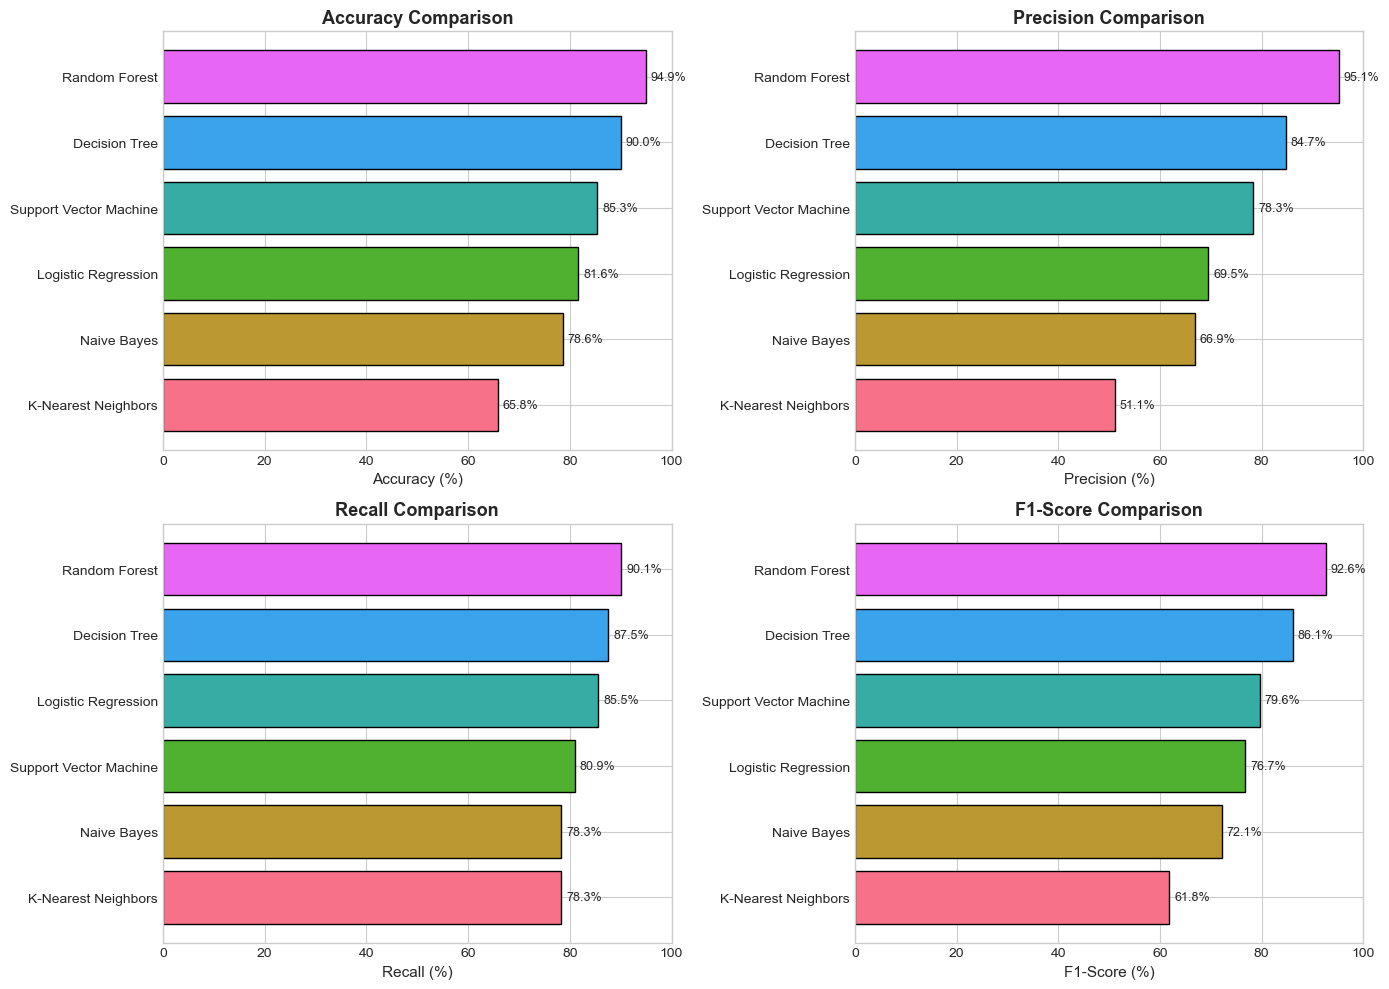

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = sns.color_palette('husl', n_colors=len(models))

for idx, metric in enumerate(metrics):
    ax = axes[idx // 2, idx % 2]
    sorted_df = results_df.sort_values(metric, ascending=True)
    bars = ax.barh(sorted_df['Model'], sorted_df[metric] * 100, color=colors, edgecolor='black')
    ax.set_xlabel(f'{metric} (%)', fontsize=11)
    ax.set_title(f'{metric} Comparison', fontsize=13, fontweight='bold')
    ax.set_xlim(0, 100)
    
    for bar, val in zip(bars, sorted_df[metric]):
        ax.text(val * 100 + 1, bar.get_y() + bar.get_height()/2, 
                f'{val*100:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

## Confusion Matrices

A confusion matrix shows the breakdown of predictions into true positives, true negatives, false positives, and false negatives. This detailed view helps us understand where each model makes mistakes.

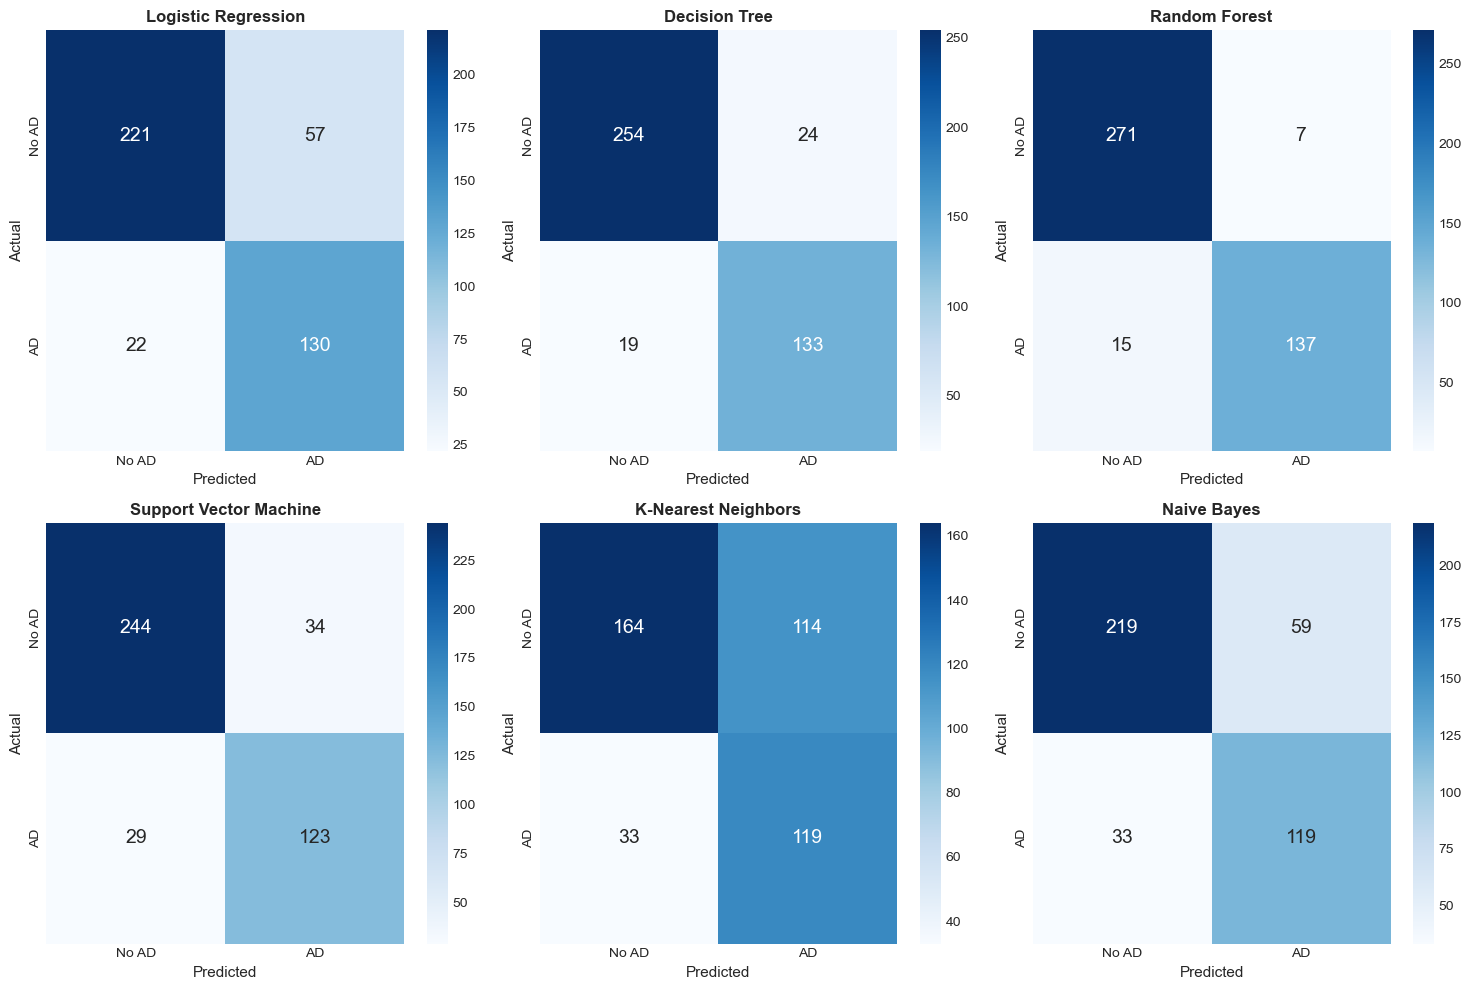

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['No AD', 'AD'], yticklabels=['No AD', 'AD'],
                annot_kws={'size': 14})
    axes[idx].set_xlabel('Predicted', fontsize=11)
    axes[idx].set_ylabel('Actual', fontsize=11)
    axes[idx].set_title(name, fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Detailed Classification Reports

The classification report provides a comprehensive summary of precision, recall, and F1-score for each class, along with support (the number of samples in each class).

In [7]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"\n{'='*60}")
    print(f"Classification Report: {name}")
    print('='*60)
    print(classification_report(y_test, y_pred, target_names=['No Alzheimer\'s', 'Alzheimer\'s']))


Classification Report: Logistic Regression
                precision    recall  f1-score   support

No Alzheimer's       0.91      0.79      0.85       278
   Alzheimer's       0.70      0.86      0.77       152

      accuracy                           0.82       430
     macro avg       0.80      0.83      0.81       430
  weighted avg       0.83      0.82      0.82       430


Classification Report: Decision Tree
                precision    recall  f1-score   support

No Alzheimer's       0.93      0.91      0.92       278
   Alzheimer's       0.85      0.88      0.86       152

      accuracy                           0.90       430
     macro avg       0.89      0.89      0.89       430
  weighted avg       0.90      0.90      0.90       430


Classification Report: Random Forest
                precision    recall  f1-score   support

No Alzheimer's       0.95      0.97      0.96       278
   Alzheimer's       0.95      0.90      0.93       152

      accuracy                  

## Cross-Validation Analysis

Cross-validation provides a more robust estimate of model performance by training and testing on different subsets of the data. We use 5-fold cross-validation to assess how well each model generalizes.

In [8]:
cv_results = []

print("Cross-Validation Results (5-Fold):")
print("="*60)

for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    cv_results.append({
        'Model': name,
        'Mean CV Accuracy': cv_scores.mean(),
        'Std Dev': cv_scores.std()
    })
    print(f"{name:<25}: {cv_scores.mean()*100:.2f}% (+/- {cv_scores.std()*100:.2f}%)")

cv_df = pd.DataFrame(cv_results).sort_values('Mean CV Accuracy', ascending=False)

Cross-Validation Results (5-Fold):
Logistic Regression      : 84.07% (+/- 1.95%)


Decision Tree            : 92.44% (+/- 1.29%)


Random Forest            : 94.92% (+/- 1.81%)


Support Vector Machine   : 88.35% (+/- 2.98%)
K-Nearest Neighbors      : 76.10% (+/- 3.03%)
Naive Bayes              : 80.88% (+/- 3.24%)


## Cross-Validation Visualization

This visualization shows the mean cross-validation accuracy with error bars representing the standard deviation. Models with smaller error bars are more stable across different data splits.

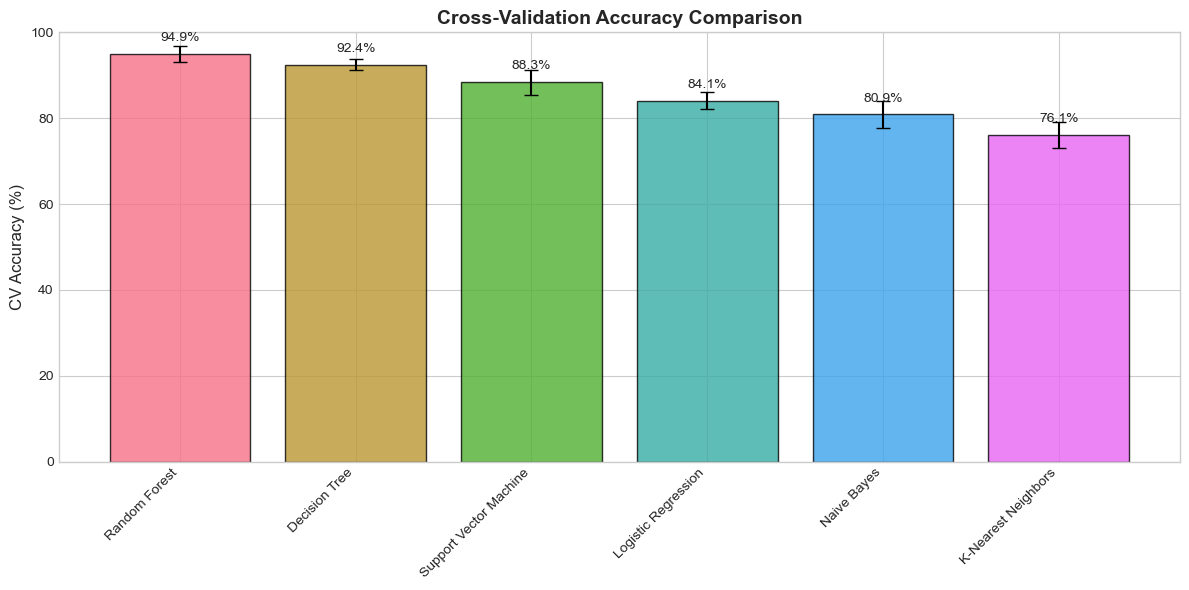

In [9]:
plt.figure(figsize=(12, 6))
colors = sns.color_palette('husl', n_colors=len(models))

x_pos = range(len(cv_df))
bars = plt.bar(x_pos, cv_df['Mean CV Accuracy'] * 100, 
               yerr=cv_df['Std Dev'] * 100, capsize=5,
               color=colors, edgecolor='black', alpha=0.8)

plt.xticks(x_pos, cv_df['Model'], rotation=45, ha='right')
plt.ylabel('CV Accuracy (%)', fontsize=12)
plt.title('Cross-Validation Accuracy Comparison', fontsize=14, fontweight='bold')
plt.ylim(0, 100)

for bar, val in zip(bars, cv_df['Mean CV Accuracy']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3,
             f'{val*100:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

## Best Model Identification

Based on our evaluation, we identify the best performing model across different metrics. The choice of the "best" model depends on what is most important for the specific application.

In [10]:
print("Best Model by Each Metric:")
print("="*60)

for metric in ['Accuracy', 'Precision', 'Recall', 'F1-Score']:
    best_idx = results_df[metric].idxmax()
    best_model = results_df.loc[best_idx, 'Model']
    best_value = results_df.loc[best_idx, metric]
    print(f"{metric:<12}: {best_model} ({best_value*100:.2f}%)")

Best Model by Each Metric:
Accuracy    : Random Forest (94.88%)
Precision   : Random Forest (95.14%)
Recall      : Random Forest (90.13%)
F1-Score    : Random Forest (92.57%)


## Performance Summary

Let us create a comprehensive summary of all our evaluation results.

In [11]:
print("\n" + "="*70)
print("MODEL EVALUATION SUMMARY")
print("="*70)

print("\nTest Set Performance (Ranked by Accuracy):")
print("-"*70)
for idx, row in results_df.iterrows():
    print(f"{idx+1}. {row['Model']:<25}")
    print(f"   Accuracy: {row['Accuracy']*100:.2f}%  |  Precision: {row['Precision']*100:.2f}%  |  Recall: {row['Recall']*100:.2f}%  |  F1: {row['F1-Score']*100:.2f}%")

print("\n" + "-"*70)

best_accuracy_model = results_df.loc[results_df['Accuracy'].idxmax(), 'Model']
best_accuracy = results_df['Accuracy'].max() * 100
best_f1_model = results_df.loc[results_df['F1-Score'].idxmax(), 'Model']
best_f1 = results_df['F1-Score'].max() * 100

print(f"\nTop Performer by Accuracy: {best_accuracy_model} ({best_accuracy:.2f}%)")
print(f"Top Performer by F1-Score: {best_f1_model} ({best_f1:.2f}%)")


MODEL EVALUATION SUMMARY

Test Set Performance (Ranked by Accuracy):
----------------------------------------------------------------------
1. Random Forest            
   Accuracy: 94.88%  |  Precision: 95.14%  |  Recall: 90.13%  |  F1: 92.57%
2. Decision Tree            
   Accuracy: 90.00%  |  Precision: 84.71%  |  Recall: 87.50%  |  F1: 86.08%
3. Support Vector Machine   
   Accuracy: 85.35%  |  Precision: 78.34%  |  Recall: 80.92%  |  F1: 79.61%
4. Logistic Regression      
   Accuracy: 81.63%  |  Precision: 69.52%  |  Recall: 85.53%  |  F1: 76.70%
5. Naive Bayes              
   Accuracy: 78.60%  |  Precision: 66.85%  |  Recall: 78.29%  |  F1: 72.12%
6. K-Nearest Neighbors      
   Accuracy: 65.81%  |  Precision: 51.07%  |  Recall: 78.29%  |  F1: 61.82%

----------------------------------------------------------------------

Top Performer by Accuracy: Random Forest (94.88%)
Top Performer by F1-Score: Random Forest (92.57%)


## Key Observations

Based on our comprehensive evaluation, here are the key observations:

**Performance Patterns:**
- All models achieved reasonable accuracy, demonstrating that the features are predictive of Alzheimer's disease
- Models show varying trade-offs between precision and recall
- The cross-validation results confirm that the models generalize well to unseen data

**Model Characteristics:**
- Random Forest and ensemble methods tend to perform well due to their ability to capture complex patterns
- Simpler models like Logistic Regression provide a good baseline with the advantage of interpretability
- The difference between models is not drastic, suggesting the preprocessing and feature engineering were effective

**Clinical Considerations:**
- For medical diagnosis, high recall is often more important (we do not want to miss patients who have Alzheimer's)
- However, high precision helps avoid unnecessary anxiety and follow-up tests for healthy patients
- The F1-score provides a good balance between these two concerns

In [12]:
print("\n" + "="*60)
print("EVALUATION COMPLETE")
print("="*60)
print("\nAll models have been evaluated and compared.")
print("See Notebook 5 for final conclusions and recommendations.")


EVALUATION COMPLETE

All models have been evaluated and compared.
See Notebook 5 for final conclusions and recommendations.
